In [51]:
from google.colab import files
uploaded = files.upload()

Saving arch.jpg to arch (1).jpg
Saving Blobs.jpg to Blobs (1).jpg
Saving Bri.jpg to Bri (1).jpg
Saving Building.jpg to Building (1).jpg
Saving Camera.jpg to Camera (1).jpg
Saving Coins.jpg to Coins (1).jpg
Saving Fingerprint.jpg to Fingerprint (1).jpg
Saving Light.jpg to Light (1).jpg
Saving Morph.jpg to Morph (1).jpg
Saving Noisy Lena.jpg to Noisy Lena (1).jpg
Saving rice.jpg to rice (1).jpg
Saving risunok.png to risunok (1).png
Saving Statue.jpg to Statue (1).jpg
Saving Truck.jpg to Truck (1).jpg


In [52]:
#1.1
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import hist

# загружаем картинку
img_risunok = cv2.imread("risunok.png")
img_risunok.shape

(400, 400, 3)

In [53]:
# вытаскиваем каналы по отдельности
B = img_risunok[:, :, 0].astype(np.float32)
G = img_risunok[:, :, 1].astype(np.float32)
R = img_risunok[:, :, 2].astype(np.float32)

In [12]:
# формула приведения к grayscale
Y = 0.2126 * R + 0.7152 * G + 0.0722 * B

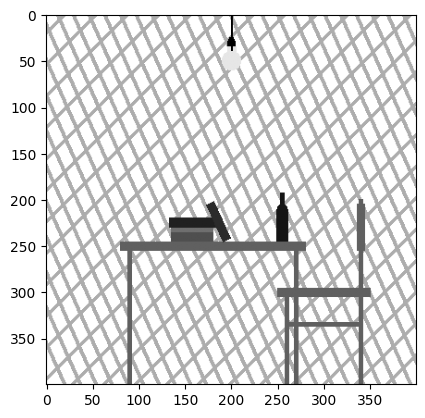

In [14]:
img_gray = np.clip(Y, 0, 255).astype(np.uint8)
plt.imshow(img_gray, cmap='gray')

In [ ]:
#1.2

In [54]:
# читаем картинки в формате grayscale
coins = cv2.imread("Coins.jpg", cv2.IMREAD_GRAYSCALE)
rice = cv2.imread("rice.jpg", cv2.IMREAD_GRAYSCALE)
arch = cv2.imread("arch.jpg", cv2.IMREAD_GRAYSCALE)
print(coins.shape)
print(rice.shape)
print(arch.shape)

(225, 225)
(255, 257)
(225, 224)


In [19]:
# создаем окно для гистограмм
plt.figure(figsize=(16, 10))

<Figure size 1600x1000 with 0 Axes>

<Figure size 1600x1000 with 0 Axes>

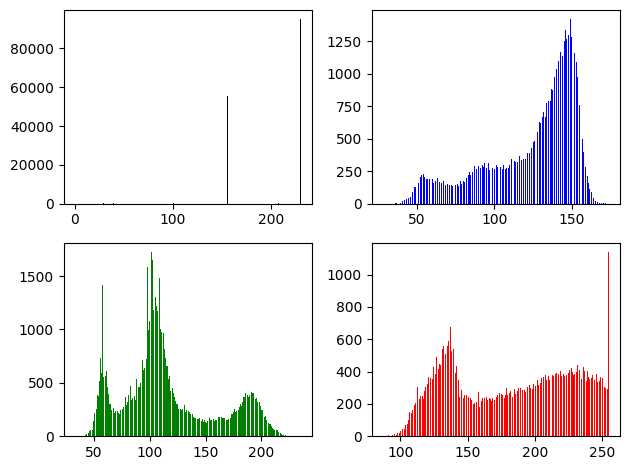

In [21]:
# простой рисунок в grayscale
plt.subplot(2, 2, 1) #позиция на полотне
plt.hist(np.ravel(img_gray), bins=256, color="black")

# coins
plt.subplot(2, 2, 2)
plt.hist(np.ravel(coins), bins=256, color="blue")

# rice
plt.subplot(2, 2, 3)
plt.hist(np.ravel(rice), bins=256, color="green")

# arch
plt.subplot(2, 2, 4)
plt.hist(np.ravel(arch), bins=256, color="red")

plt.tight_layout()
plt.show()


In [ ]:
''' Гистограммы показывают распределение яркостей. Изображение coins в целом является светлым и однородным.
изображение rice хорошо подходит для бинаризации, изображение arch имеет высокую контрастность

In [ ]:
# 1.3

In [22]:
def piecewise_linear_transform(image, r1, s1, r2, s2):
    # cоздаем пустую таблицу поиска на 256 значений
    lut = np.zeros(256, dtype=np.uint8)

    # 1й отрезок от 0 до r1
    # np.linspace создает равномерное распределение от 0 до s1 с r1+1 кол-вом шагов
    lut[0:r1+1] = np.linspace(0, s1, r1+1)

    # 2й отрезок от r1 до r2
    lut[r1+1:r2+1] = np.linspace(s1, s2, r2 - r1)

    # 3ий отрезок от r2 до 255
    lut[r2+1:256] = np.linspace(s2, 255, 255 - r2)

    # применяем таблицу к изображению
    return cv2.LUT(image, lut)

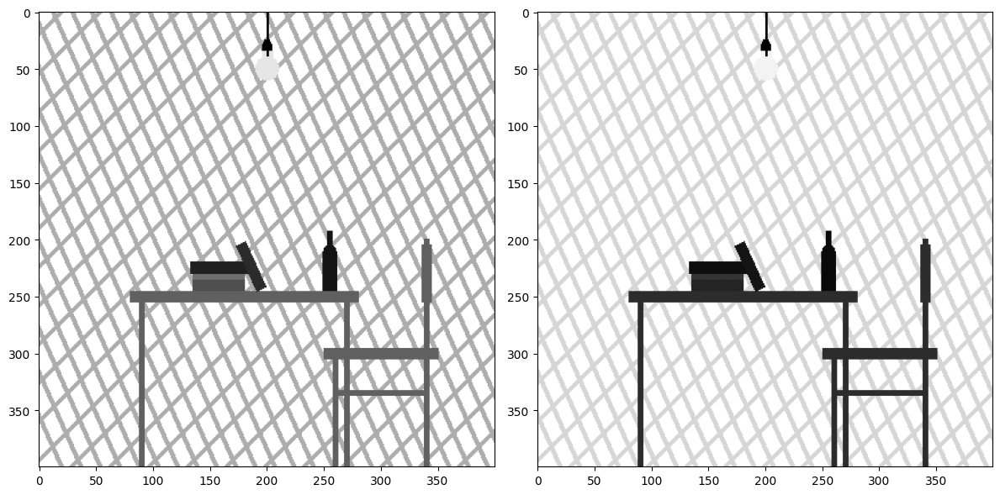

In [23]:
# зададим точки излома (r1, s1) и (r2, s2)
r1, s1 = 100, 50
r2, s2 = 150, 200
# преобразуем серый простой рисунок
img_transformed = piecewise_linear_transform(img_gray, r1, s1, r2, s2)

# выводим результат
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_gray, cmap='gray')

plt.subplot(1, 2, 2)
plt.imshow(img_transformed, cmap='gray')

plt.tight_layout()
plt.show()

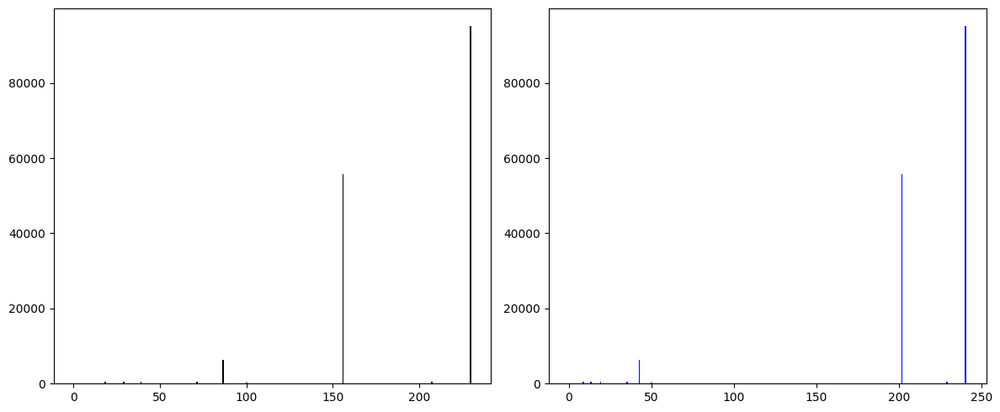

In [25]:
plt.figure(figsize=(12, 5))

# гистограмма grayscale
plt.subplot(1, 2, 1)
plt.hist(np.ravel(img_gray), bins=256, color="black")

# гистограмма после кусочно-линейного преобразования
plt.subplot(1, 2, 2)
plt.hist(np.ravel(img_transformed), bins=256, color="blue")

plt.tight_layout()
plt.show()

In [ ]:
# после преобразования темные пиксели стали еще темнее, а светлые еще светлее. Повысился контраст

In [ ]:
# 1.4

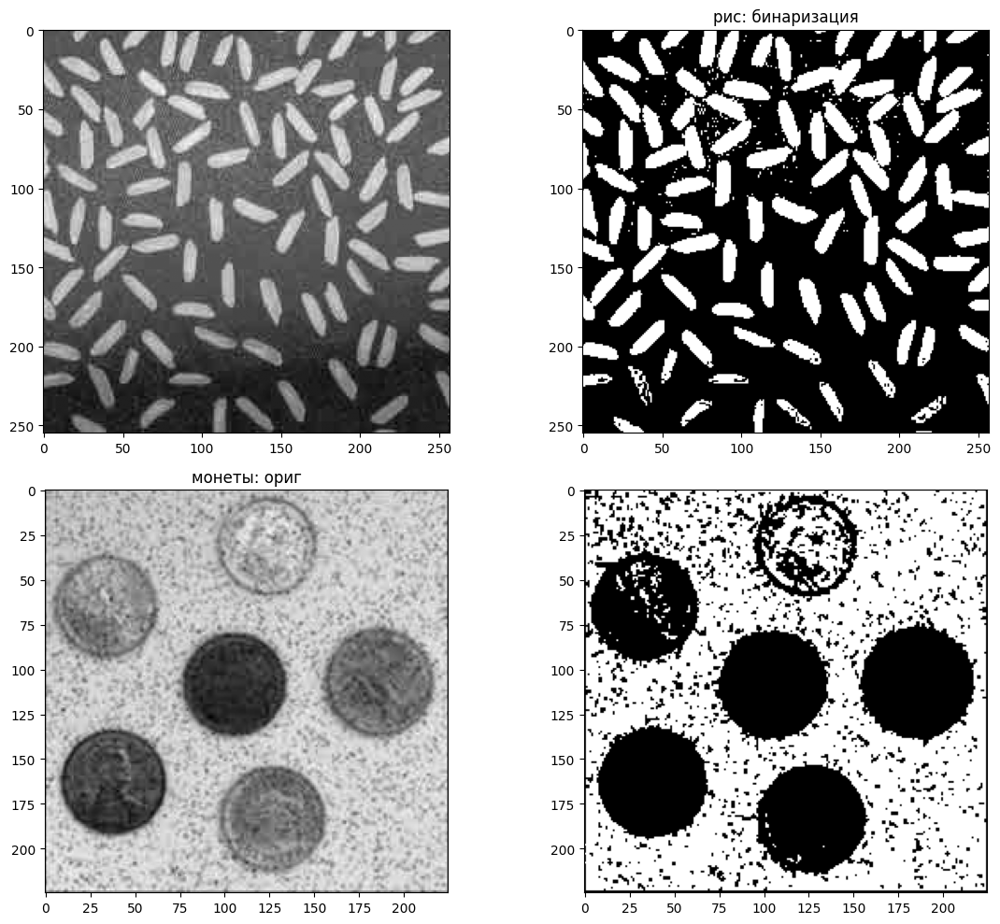

In [55]:
# бинаризация для rice
_, rice_thresh = cv2.threshold(rice, 127, 255, cv2.THRESH_BINARY)

# бинаризация для coins, порог определяется автоматически через алгоритм otsu
ret_otsu, coins_otsu = cv2.threshold(coins, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# отображение
plt.figure(figsize=(12, 10))

# рис, ориг и бинаризация
plt.subplot(2, 2, 1)
plt.imshow(rice, cmap='gray')

plt.subplot(2, 2, 2)
plt.imshow(rice_thresh, cmap='gray')
plt.title("рис: бинаризация")


# монеты, ориг и бинаризация
plt.subplot(2, 2, 3)
plt.imshow(coins, cmap='gray')
plt.title("монеты: ориг")

plt.subplot(2, 2, 4)
plt.imshow(coins_thresh, cmap='gray')

plt.tight_layout()
plt.show()

In [31]:
# получаем статистику объектов
_, _, stats, _ = cv2.connectedComponentsWithStats(rice_thresh, connectivity=8)

#берем площади всех объектов
areas = stats[1:, cv2.CC_STAT_AREA]

valid_objects = np.sum(areas > 20)

print(f"Количество зерен риса: {valid_objects}")

Количество зерен риса: 87


In [33]:
# инвертируем картинку, чтобы монеты стали белыми
coins_inverted = cv2.bitwise_not(coins_otsu)

# ищем монеты
_, _, stats, _ = cv2.connectedComponentsWithStats(coins_inverted, connectivity=8)

# берем их площади
areas = stats[1:, cv2.CC_STAT_AREA]

# считаем больше 150 пикселей
valid_coins = np.sum(areas > 150)

print(f"Количество найденных монет: {valid_coins}")

Количество найденных монет: 6


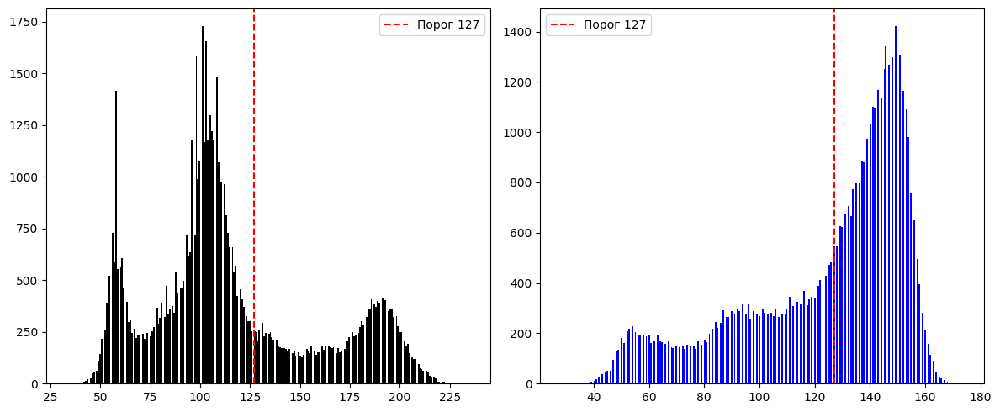

In [28]:
plt.figure(figsize=(12, 5))

# гистограмма риса
plt.subplot(1, 2, 1)
plt.hist(np.ravel(rice), bins=256, color="black")
# вертикальная красная линия для порога
plt.axvline(x=127, color='red', linestyle='--', label='Порог 127')
plt.legend()

# гистограмма для монет
plt.subplot(1, 2, 2)
plt.hist(np.ravel(coins), bins=256, color="blue")
plt.axvline(x=127, color='red', linestyle='--', label='Порог 127')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# для риса фиксированный средний порог очень хорошо подошел, удалось легко отделить светлые зерна от темного фона. С монетами такое не сработало, пришлось применять алгоритм поиска порогового значения OTSU, для локализации инвертировали изображение

In [ ]:
# Задание 2

In [34]:
img_light = cv2.imread("Light.jpg")
img_camera = cv2.imread("Camera.jpg")
img_building = cv2.imread("Building.jpg")
img_truck = cv2.imread("Truck.jpg")
img_statue = cv2.imread("Statue.jpg")
img_lena = cv2.imread("Noisy Lena.jpg")
img_bri = cv2.imread("Bri.jpg")

In [38]:
images_list = [
    (img_light, "Light"),
    (img_camera, "Camera"),
    (img_building, "Building"),
    (img_truck, "Truck"),
    (img_statue, "Statue"),
    (img_lena, "Noisy Lena"),
    (img_bri, "Bri")
]

kernels = [3, 5, 7, 9]

In [35]:
def show_filters(img, k_size, title_prefix):
    # применяем три фильтра
    blur = cv2.blur(img, (k_size, k_size))
    gauss = cv2.GaussianBlur(img, (k_size, k_size), 0)
    median = cv2.medianBlur(img, k_size)

    # создаем полотно, одна строка 4 колонки
    plt.figure(figsize=(20, 5))
    plt.suptitle(f"{title_prefix} | Размер ядра: {k_size}x{k_size}", fontsize=16)

    # переводим BGR в RGB для отображения
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 4, 1)
    plt.imshow(img_rgb)
    plt.title("Оригинал")

    plt.subplot(1, 4, 2)
    plt.imshow(cv2.cvtColor(blur, cv2.COLOR_BGR2RGB))
    plt.title("Усредняющий")

    plt.subplot(1, 4, 3)
    plt.imshow(cv2.cvtColor(gauss, cv2.COLOR_BGR2RGB))
    plt.title("Гаусс")

    plt.subplot(1, 4, 4)
    plt.imshow(cv2.cvtColor(median, cv2.COLOR_BGR2RGB))
    plt.title("Медианный")

    plt.tight_layout()
    plt.show()

In [42]:
def show_histograms(img, k_size, title_prefix):
    blur = cv2.blur(img, (k_size, k_size))
    gauss = cv2.GaussianBlur(img, (k_size, k_size), 0)
    median = cv2.medianBlur(img, k_size)

    gray_orig = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray_blur = cv2.cvtColor(blur, cv2.COLOR_BGR2GRAY)
    gray_gauss = cv2.cvtColor(gauss, cv2.COLOR_BGR2GRAY)
    gray_median = cv2.cvtColor(median, cv2.COLOR_BGR2GRAY)

    plt.figure(figsize=(20, 5))
    plt.suptitle(f"Гистограммы: {title_prefix} | Ядро: {k_size}x{k_size}", fontsize=16)

    plt.subplot(1, 4, 1)
    plt.hist(np.ravel(gray_orig), bins=256, color="black", alpha=0.6)
    plt.title("Оригинал")

    plt.subplot(1, 4, 2)
    plt.hist(np.ravel(gray_blur), bins=256, color="blue", alpha=0.6)
    plt.title("Усредняющий")

    plt.subplot(1, 4, 3)
    plt.hist(np.ravel(gray_gauss), bins=256, color="green", alpha=0.6)
    plt.title("Гаусс")

    plt.subplot(1, 4, 4)
    plt.hist(np.ravel(gray_median), bins=256, color="red", alpha=0.6)
    plt.title("Медианный")

    plt.tight_layout()
    plt.show()

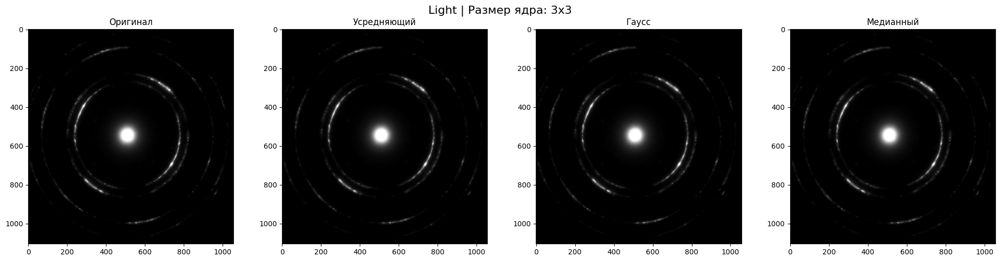

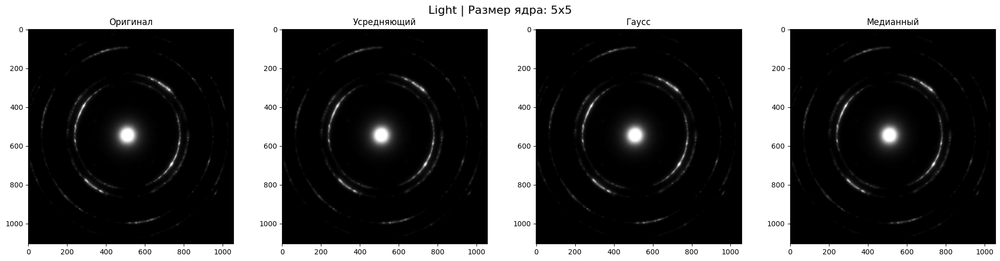

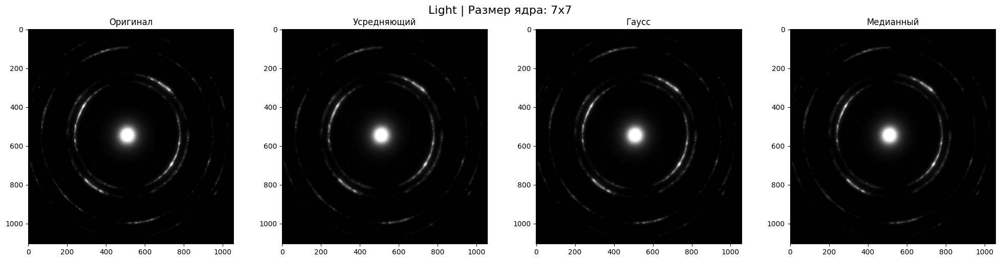

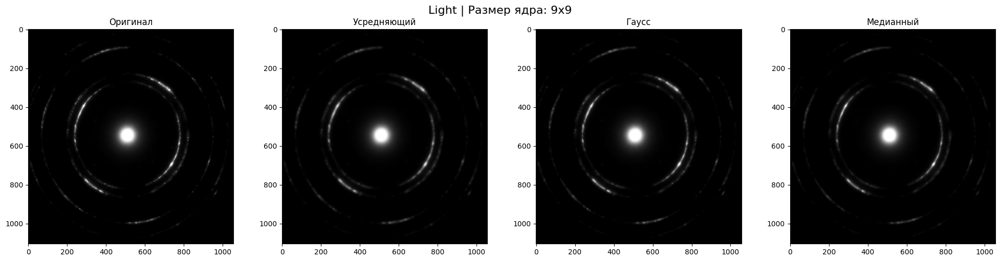

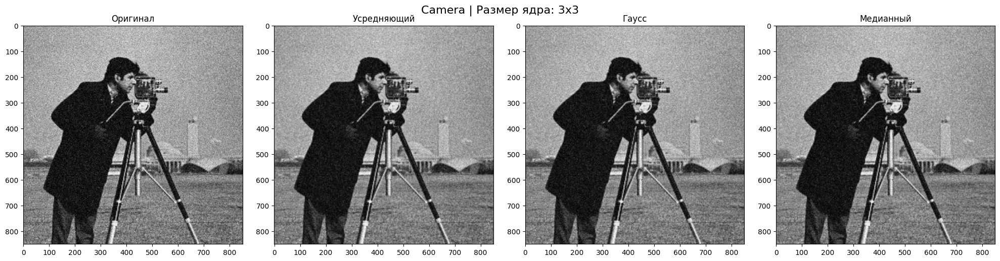

...

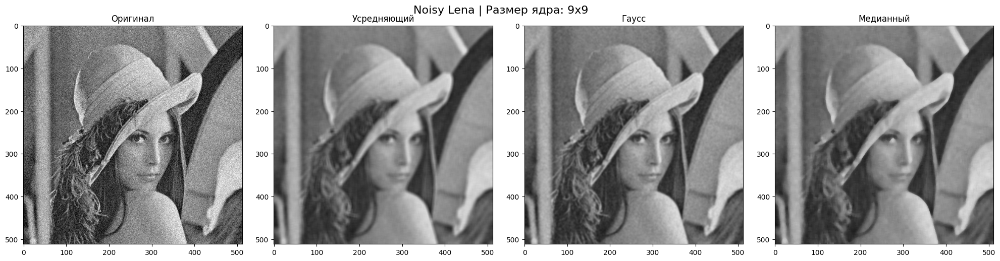

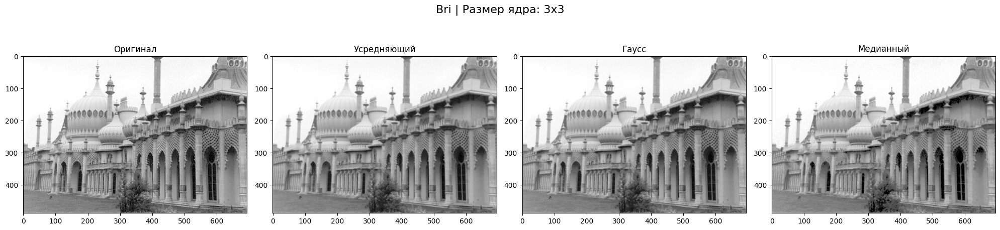

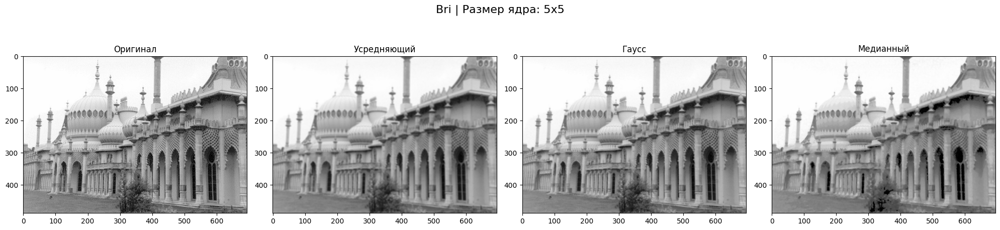

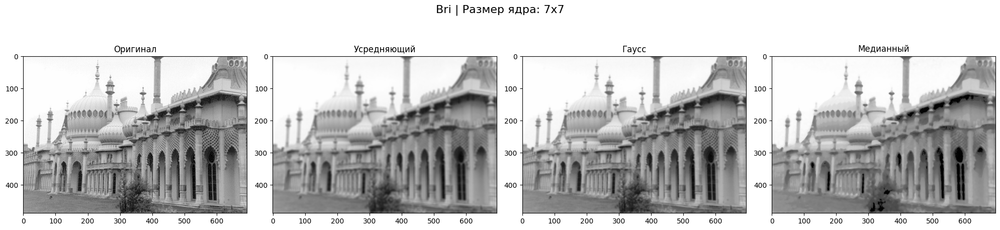

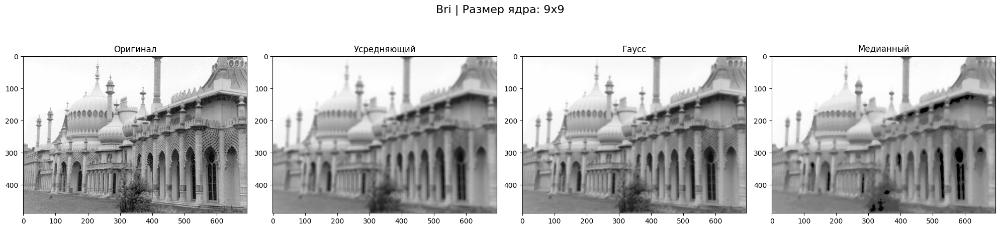

In [39]:
for img, name in images_list:
    for k in kernels:
        show_filters(img, k, name)

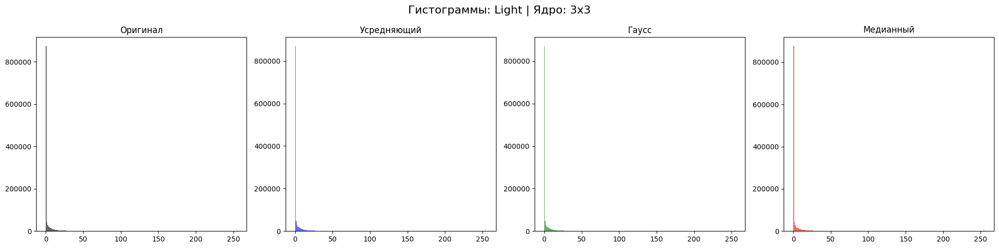

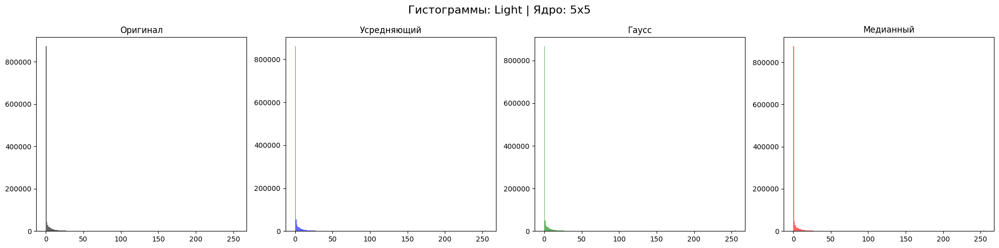

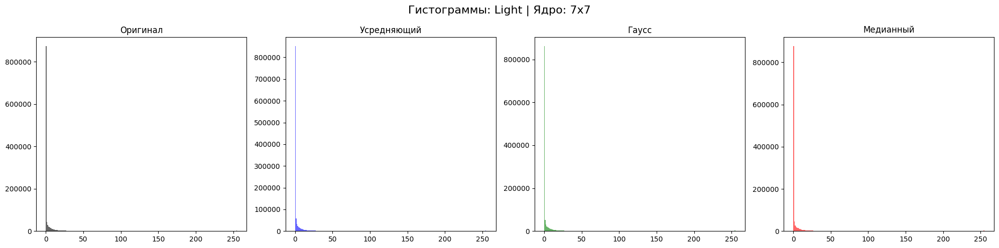

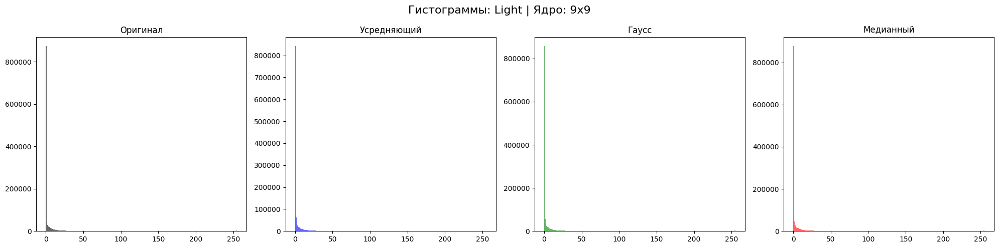

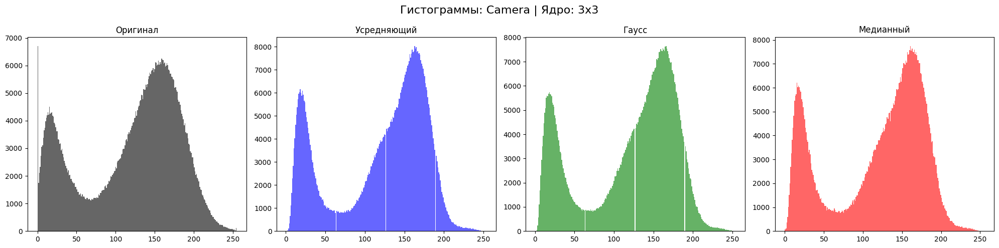

...

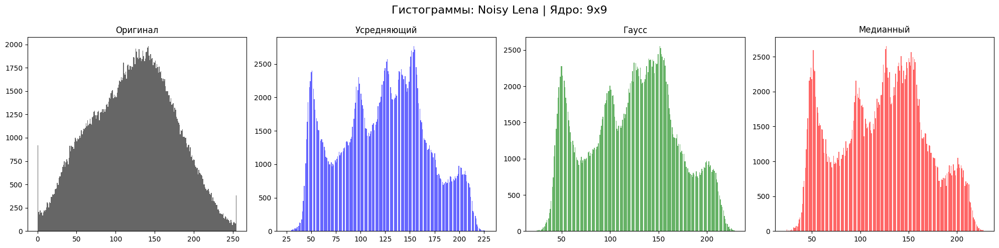

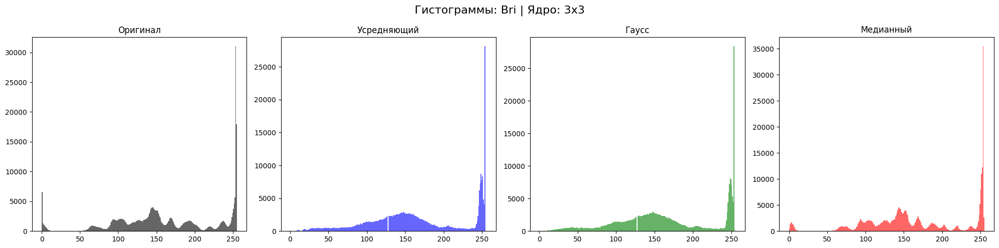

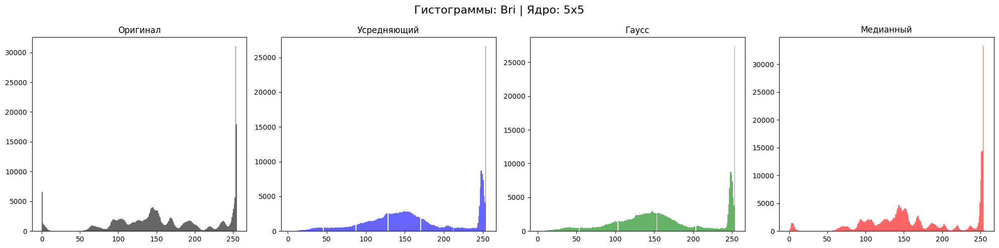

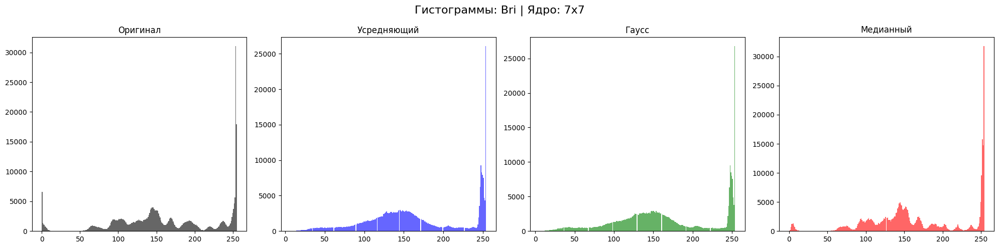

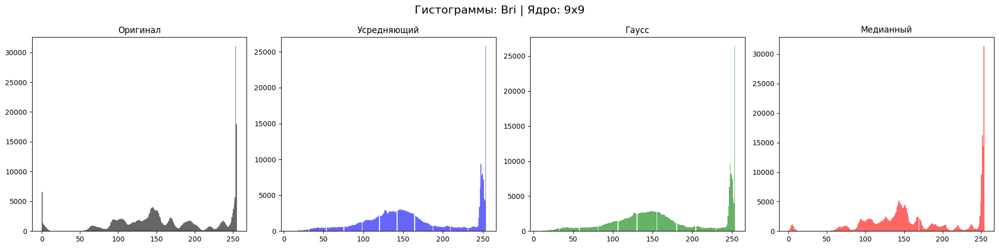

In [43]:
for img, name in images_list:
    for k in kernels:
        show_histograms(img, k, name)

In [45]:
''' Выбор фильтра зависит от типа шума: медианный для точечного, Гаусс для плавного, усредняющий для грубого сглаживания
Размер ядра напрямую влияет на силу размытия: чем оно больше, тем меньше шума остается, но и тем больше деталей теряется
сильное увеличение ядра (9x9) приводит к потере информации и сильному падению контраста'''

' Выбор фильтра зависит от типа шума: медианный для точечного, Гаусс для плавного, усредняющий для грубого сглаживания\nРазмер ядра напрямую влияет на силу размытия: чем оно больше, тем меньше шума остается, но и тем больше деталей теряется \nсильное увеличение ядра (9x9) приводит к потере информации и сильному падению контраста'

In [ ]:
# 2.2

In [46]:
def show_edge_filters(img, title_prefix):
    # переводим изображение в grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # ядра фильтров
    # Превитт (Gx и Gy)
    prewitt_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    prewitt_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], np.float32)

    # Собель (Gx и Gy)
    sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
    sobel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], np.float32)

    # Робертс (Gx и Gy)
    roberts_x = np.array([[1, 0], [0, -1]], np.float32)
    roberts_y = np.array([[0, 1], [-1, 0]], np.float32)

    # применение фильтров
    # для каждого фильтра считаем градиент по X и Y, а затем берем их сумму по модулю (convertScaleAbs)

    p_x = cv2.filter2D(gray, cv2.CV_64F, prewitt_x)
    p_y = cv2.filter2D(gray, cv2.CV_64F, prewitt_y)
    prewitt = cv2.addWeighted(cv2.convertScaleAbs(p_x), 0.5, cv2.convertScaleAbs(p_y), 0.5, 0)

    s_x = cv2.filter2D(gray, cv2.CV_64F, sobel_x)
    s_y = cv2.filter2D(gray, cv2.CV_64F, sobel_y)
    sobel = cv2.addWeighted(cv2.convertScaleAbs(s_x), 0.5, cv2.convertScaleAbs(s_y), 0.5, 0)

    r_x = cv2.filter2D(gray, cv2.CV_64F, roberts_x)
    r_y = cv2.filter2D(gray, cv2.CV_64F, roberts_y)
    roberts = cv2.addWeighted(cv2.convertScaleAbs(r_x), 0.5, cv2.convertScaleAbs(r_y), 0.5, 0)

    # отображение
    plt.figure(figsize=(20, 5))
    plt.suptitle(f"Выделение границ: {title_prefix}", fontsize=16)

    plt.subplot(1, 4, 1)
    plt.imshow(gray, cmap='gray')
    plt.title("Оригинал (Grayscale)")

    plt.subplot(1, 4, 2)
    plt.imshow(prewitt, cmap='gray')
    plt.title("Превитт")

    plt.subplot(1, 4, 3)
    plt.imshow(sobel, cmap='gray')
    plt.title("Собель")

    plt.subplot(1, 4, 4)
    plt.imshow(roberts, cmap='gray')
    plt.title("Робертс")

    plt.tight_layout()
    plt.show()

In [48]:
def show_edge_histograms(img, title_prefix):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    prewitt_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    prewitt_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], np.float32)

    sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
    sobel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], np.float32)

    roberts_x = np.array([[1, 0], [0, -1]], np.float32)
    roberts_y = np.array([[0, 1], [-1, 0]], np.float32)

    p_x = cv2.filter2D(gray, cv2.CV_64F, prewitt_x)
    p_y = cv2.filter2D(gray, cv2.CV_64F, prewitt_y)
    prewitt = cv2.addWeighted(cv2.convertScaleAbs(p_x), 0.5, cv2.convertScaleAbs(p_y), 0.5, 0)

    s_x = cv2.filter2D(gray, cv2.CV_64F, sobel_x)
    s_y = cv2.filter2D(gray, cv2.CV_64F, sobel_y)
    sobel = cv2.addWeighted(cv2.convertScaleAbs(s_x), 0.5, cv2.convertScaleAbs(s_y), 0.5, 0)

    r_x = cv2.filter2D(gray, cv2.CV_64F, roberts_x)
    r_y = cv2.filter2D(gray, cv2.CV_64F, roberts_y)
    roberts = cv2.addWeighted(cv2.convertScaleAbs(r_x), 0.5, cv2.convertScaleAbs(r_y), 0.5, 0)

    plt.figure(figsize=(20, 5))
    plt.suptitle(f"Гистограммы границ: {title_prefix}", fontsize=16)

    plt.subplot(1, 4, 1)
    plt.hist(np.ravel(gray), bins=256, color='black', alpha=0.7)
    plt.title("ориг")

    plt.subplot(1, 4, 2)
    plt.hist(np.ravel(prewitt), bins=256, color='blue', alpha=0.7)
    plt.title("Превитт")

    plt.subplot(1, 4, 3)
    plt.hist(np.ravel(sobel), bins=256, color='green', alpha=0.7)
    plt.title("Собель")

    plt.subplot(1, 4, 4)
    plt.hist(np.ravel(roberts), bins=256, color='red', alpha=0.7)
    plt.title("Робертс")

    plt.tight_layout()
    plt.show()

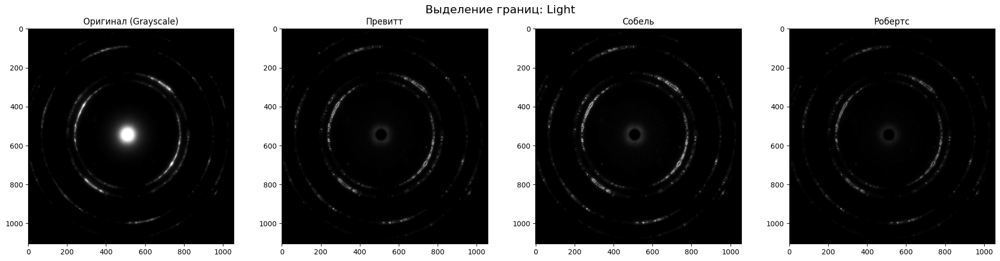

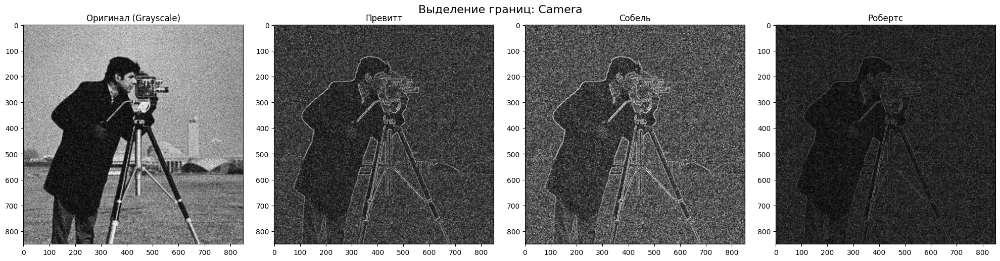

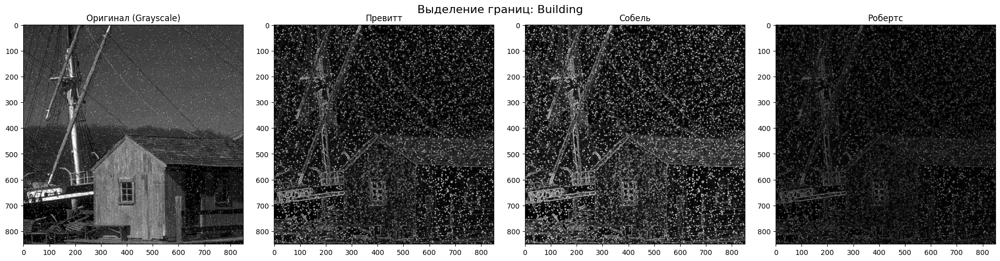

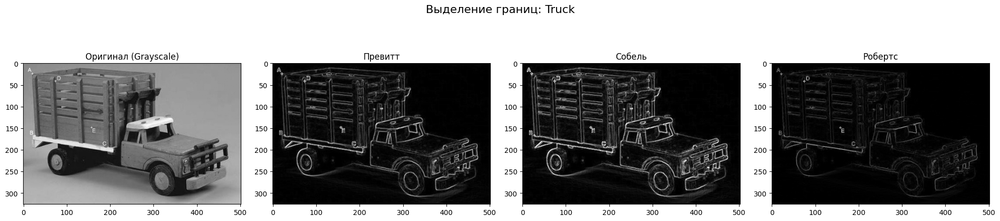

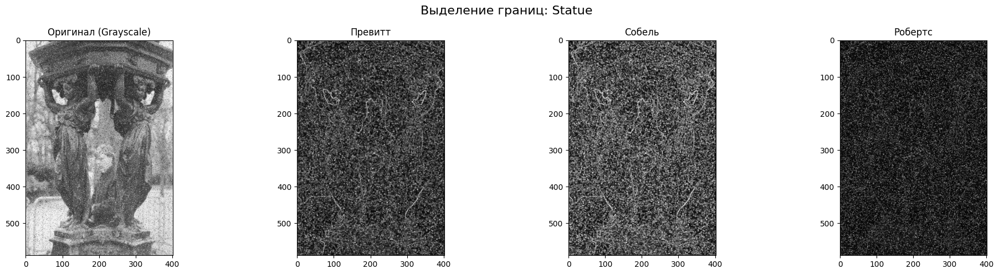

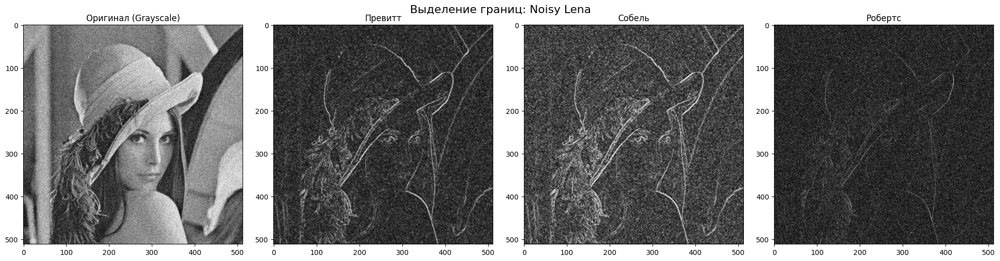

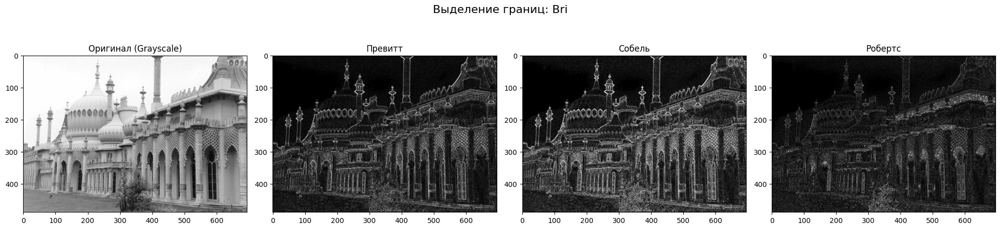

In [47]:
for img, name in images_list:
    show_edge_filters(img, name)

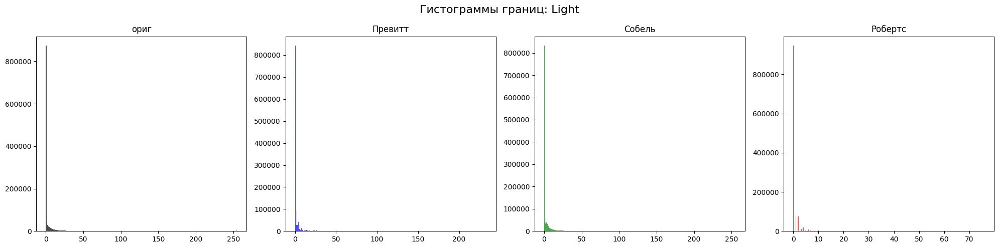

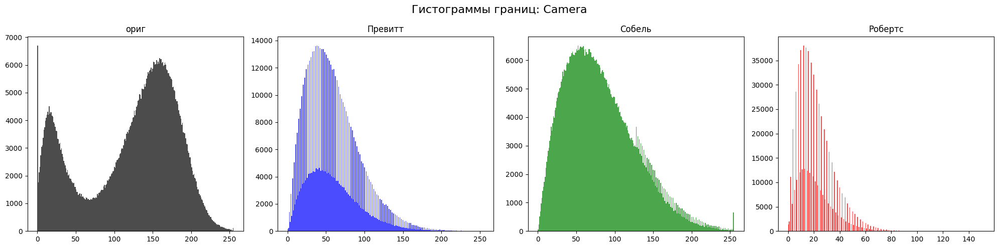

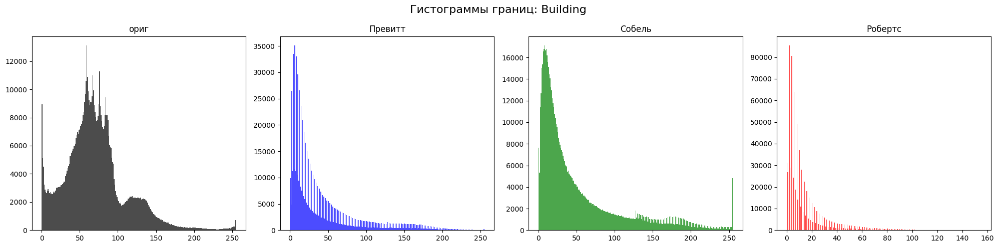

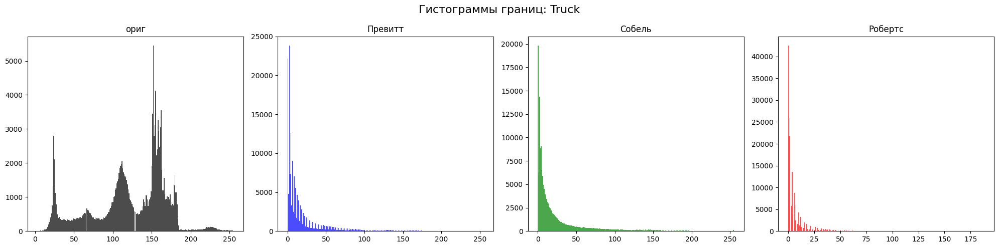

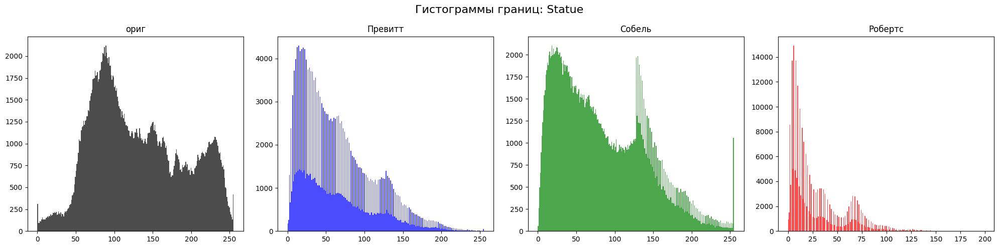

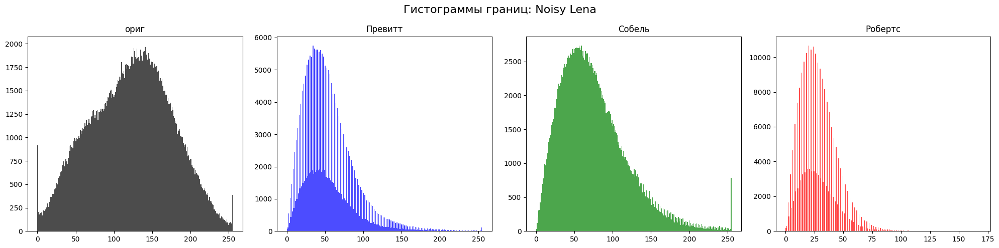

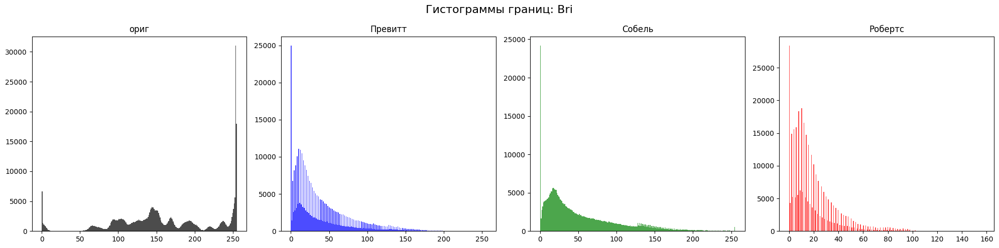

In [50]:
for img, name in images_list:
    show_edge_histograms(img, name)

In [ ]:
'''
Фильтры Превитта, Собеля и Робертса превращают изображение в набор контуров
Фон становится черным,все границы и перепады яркости белыми
Собель дает более четкие и чистые линии, Робертс  самые тонкие, но сильнее реагирует на шум, а Превитт среднее

In [ ]:
# 3.1

In [59]:
def show_morphology_detailed(img, operation_name):
    # Тип ядра, размер, название
    kernels_info = [
        (cv2.MORPH_CROSS, 3, "Крест 3x3"),
        (cv2.MORPH_CROSS, 5, "Крест 5x5"),
        (cv2.MORPH_RECT, 3, "Прямоуг. 3x3"),
        (cv2.MORPH_RECT, 5, "Прямоуг. 5x5")
    ]

    iterations = [1, 3, 5]

    # сетка 4х4, 1 колонка для оригинала, 3 для итераций
    fig, axes = plt.subplots(4, 4, figsize=(16, 16))
    fig.suptitle(f"Операция: {operation_name}", fontsize=20, y=0.92)

    for row, (shape_type, size, shape_name) in enumerate(kernels_info):

        # в первом столбце всегда оригинал
        axes[row, 0].imshow(img, cmap='gray')
        axes[row, 0].set_title("Оригинал")

        for col, iters in enumerate(iterations, start=1):
            # создаем ядро нужной формы и размера
            kernel = cv2.getStructuringElement(shape_type, (size, size))

            # операция
            if operation_name == "Дилатация":
                result = cv2.dilate(img, kernel, iterations=iters)
            else:
                result = cv2.erode(img, kernel, iterations=iters)

            axes[row, col].imshow(result, cmap='gray')
            axes[row, col].set_title(f"{shape_name} | {iters} итер.")

    plt.tight_layout()
    plt.show()

******************************************************************************************************************************************************, Дилатация


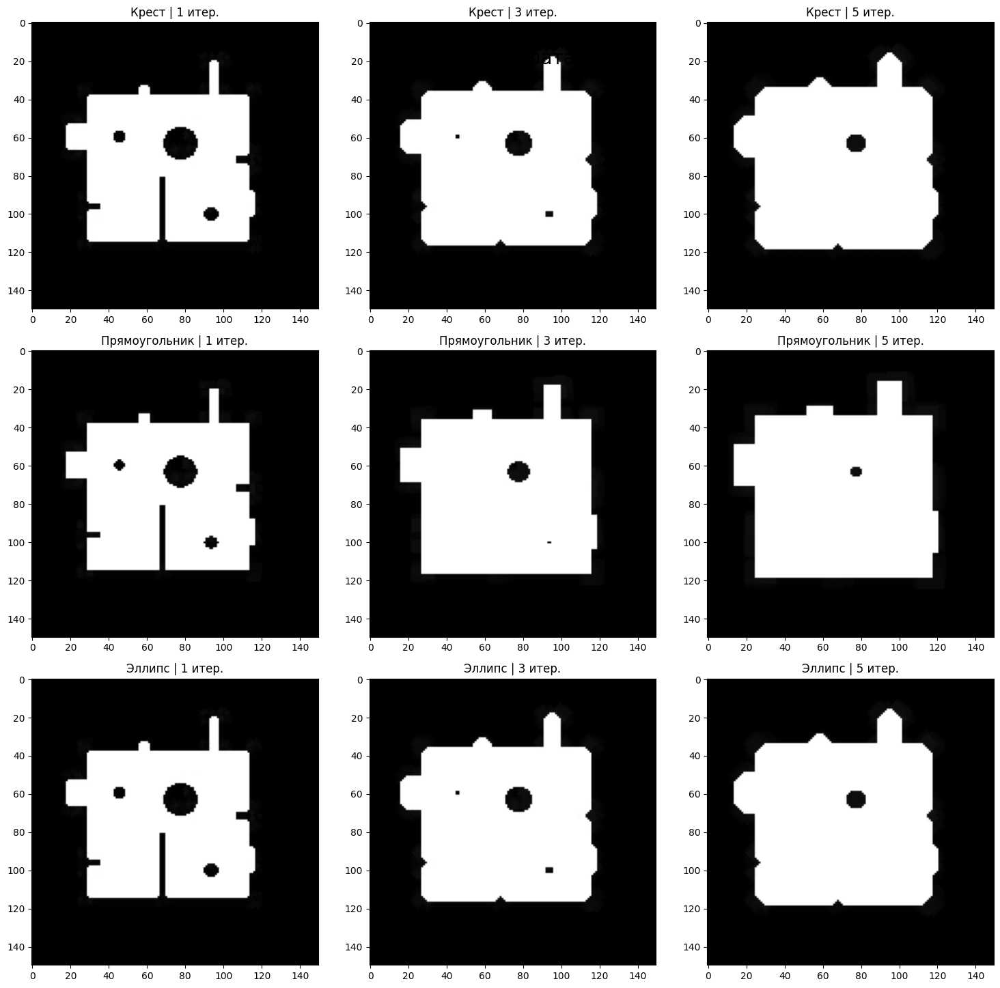

******************************************************************************************************************************************************, Эрозия


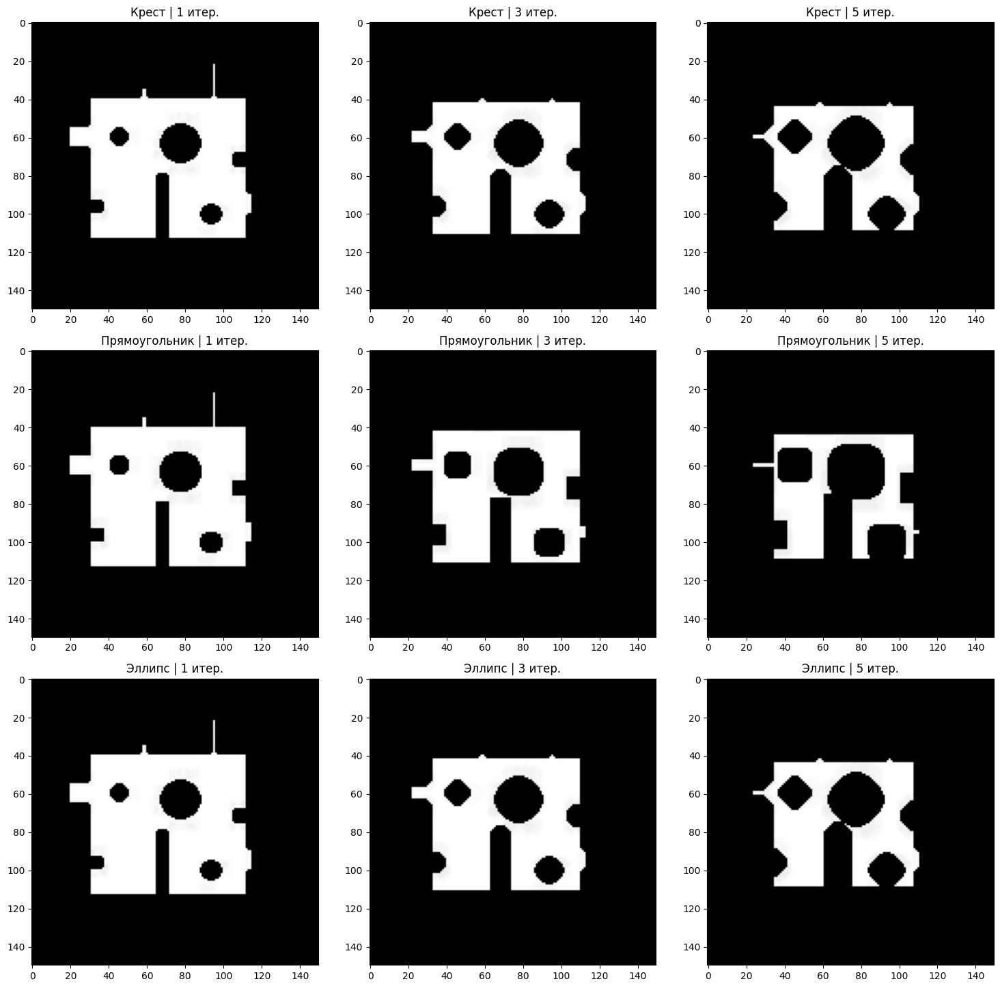

In [62]:
print(f'{"*" * 150}, Дилатация')
show_morphology(gray_morph, "Дилатация")
print(f'{"*" * 150}, Эрозия')
show_morphology(gray_morph, "Эрозия")

In [65]:
'''
При дилатации белая фигура расширяется, черные пятна стягиваются
Прямоугольник расширяет форму по горизонтали и вертикали
Эллипс расширяет плавнее, скругляя углы
От креста прямые углы сохраняют форму, но на углах появляются ступеньки

При эрозии наоборот, расширяются черные пятна
Крест сжимает фигуру по направлению к центру
Прямоугольник сжимает фигуру равномерно со всех сторон
Аналогично элипс делает наиболее плавное сжатие'''

'\nПри дилатации белая фигура расширяется, черные пятна стягиваются\nПрямоугольник расширяет форму по горизонтали и вертикали\nЭллипс расширяет плавнее, скругляя углы\nОт креста прямые углы сохраняют форму, но на углах появляются ступеньки\n\nПри эрозии наоборот, расширяются черные пятна\nКрест сжимает фигуру по направлению к центру\nПрямоугольник сжимает фигуру равномерно со всех сторон\nАналогично элипс делает наиболее плавное сжатие'

In [71]:
img_blobs = cv2.imread("Blobs.jpg", cv2.IMREAD_GRAYSCALE)

def show_boundaries(img, title_prefix):
    # cписок комбинаций ядер форма, размер, название
    kernels_info = [
        (cv2.MORPH_CROSS, 3, "Крест 3x3"),
        (cv2.MORPH_CROSS, 5, "Крест 5x5"),
        (cv2.MORPH_RECT, 3, "Прямоуг. 3x3"),
        (cv2.MORPH_RECT, 5, "Прямоуг. 5x5"),
        (cv2.MORPH_ELLIPSE, 3, "Эллипс 3x3"),
        (cv2.MORPH_ELLIPSE, 5, "Эллипс 5x5")
    ]

    # создаем сетку 2 строки ориг+границы, 6 колонок по числу ядер
    fig, axes = plt.subplots(2, 6, figsize=(20, 7))
    fig.suptitle(f"Выделение границ: {title_prefix}", fontsize=20)

    # в пересечении (0,0) показываем оригинал
    axes[0, 0].imshow(img, cmap='gray')
    axes[0, 0].set_title("Оригинал")

    # убираем оси у остальных ячеек верхней строки
    for i in range(1, 6):
        axes[0, i].axis('off')


    # нижняя строка, результаты для всех ядер
    for col, (shape_type, size, shape_name) in enumerate(kernels_info):
        # создаем ядро
        kernel = cv2.getStructuringElement(shape_type, (size, size))

        # эрозия (er(A, B))
        eroded = cv2.erode(img, kernel, iterations=1)

        # вычитание: A - er(A,B)
        # cv2.subtract делает вычитание (все, что  меньше 0, станет 0)
        boundary = cv2.subtract(img, eroded)

        # отображаем нижнюю строку
        axes[1, col].imshow(boundary, cmap='gray')
        axes[1, col].set_title(f"Границы: {shape_name}")

    plt.tight_layout()
    plt.show()

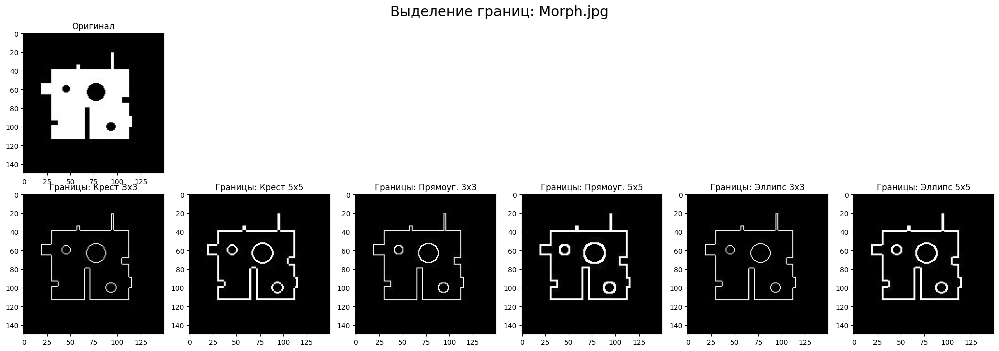

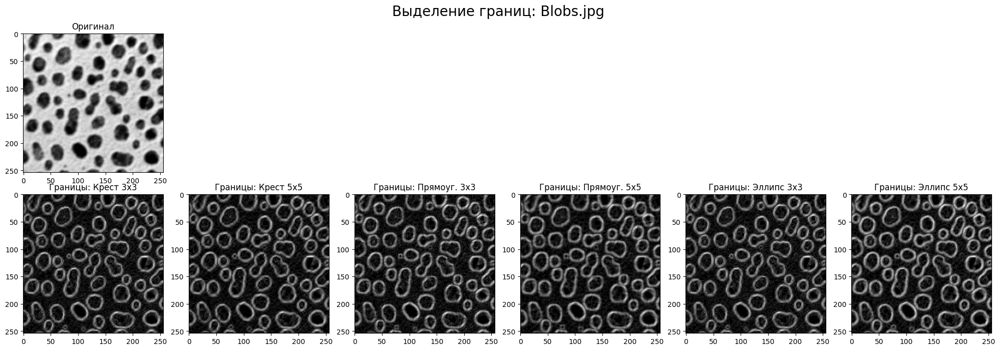

In [72]:
show_boundaries(gray_morph, "Morph.jpg")
show_boundaries(img_blobs, "Blobs.jpg")

In [ ]:
'''
Для бинарных изображений лучше всего использовать ядро 3x3 любой формы. Оно дает тонкие и точные границы, размер 5x5 делает контуры слишком толстыми
Для полутоновых изображений лучше крест 3x3. Он лучше выделяет границы и меньше расширяет контуры, хотя  шум все равно остается

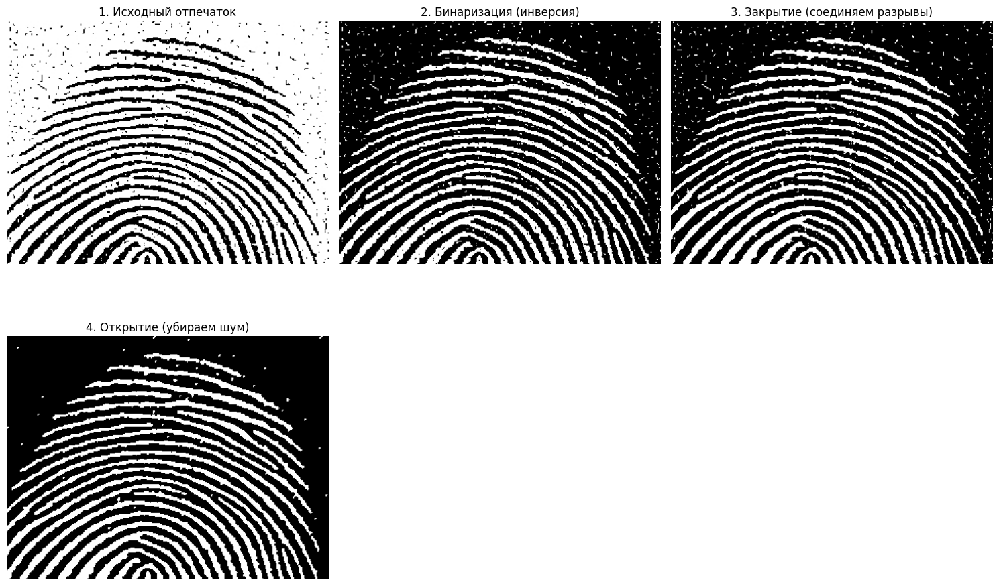

Последовательность:
1. Бинаризация с инверсией линии становятся белыми на черном фоне
2. Закрытие эллипсом 3x3 соединяем разрывы между линиями
3. Открытие эллипсом 2x2 убираем мелкий шум
4. Эрозия эллипсом 2x2 убираем остаточный шум


In [74]:
fingerprint = cv2.imread("Fingerprint.jpg", cv2.IMREAD_GRAYSCALE)
#отображаем исходное
plt.figure(figsize=(15, 10))
plt.subplot(2, 3, 1)
plt.imshow(fingerprint, cmap='gray')
plt.title('1. Исходный отпечаток')
plt.axis('off')

#1.Бинаризация (инвертируем, чтобы линии были белыми на черном)
_, binary = cv2.threshold(fingerprint, 127, 255, cv2.THRESH_BINARY_INV)
plt.subplot(2, 3, 2)
plt.imshow(binary, cmap='gray')
plt.title('2. Бинаризация (инверсия)')
plt.axis('off')

#2.Закрытие (дилатация -> эрозия) дилатация соединяет близкие разорванные линии, эрозия восстанавливает толщину
struct_elem = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, struct_elem, iterations=1)
plt.subplot(2, 3, 3)
plt.imshow(closed, cmap='gray')
plt.title('3. Закрытие (соединяем разрывы)') #соединяем разрывы между линиями
plt.axis('off')

#3.Открытие (эрозия -> дилатация), эрозия убирает мелкие точки, дилатация восстанавливает основные линии
struct_elem2 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2, 2))
opened = cv2.morphologyEx(closed, cv2.MORPH_OPEN, struct_elem2, iterations=1)
plt.subplot(2, 3, 4)
plt.imshow(opened, cmap='gray')
plt.title('4. Открытие (убираем шум)')
plt.axis('off')


#4. Доп. эрозия
cleaned = cv2.erode(opened, struct_elem2, iterations=1)

plt.tight_layout()
plt.show()

print("Последовательность:")
print("1. Бинаризация с инверсией линии становятся белыми на черном фоне")
print("2. Закрытие эллипсом 3x3 соединяем разрывы между линиями")
print("3. Открытие эллипсом 2x2 убираем мелкий шум")
print("4. Эрозия эллипсом 2x2 убираем остаточный шум")